In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler


header = ['comment_id', 'text', 'date', 'song', 'artist', 'kendrick_score', 'drake_score']
dataset = pd.read_csv(filepath_or_buffer='./cleaned_comments/cleaned_comments.csv',  delimiter=',', names=header, skiprows=1)
dataset

,comment_id,text,date,song,artist,kendrick_score,drake_score
0,Ugzc5Srhx8p6qzdSjvB4AaABAg,Kendrick responded so fast I didnt know Drake ...,2024-05-04 12:59:37+00:00,Family_Matters,BagOnly_Drake,2,-1
1,UgxGl-mJYHo4mzjNy0R4AaABAg,Beat switches each time a different ghost writ...,2024-05-04 08:41:23+00:00,Family_Matters,BagOnly_Drake,0,-2
2,Ugw8sI-rRjgKXTUCBFV4AaABAg,Kendrick had a diss ready for this song not ev...,2024-05-04 05:18:35+00:00,Family_Matters,BagOnly_Drake,2,0
3,UgzkG6vRyh2O9FOlnJR4AaABAg,Imagine sitting down in a group and writing th...,2024-05-04 17:04:41+00:00,Family_Matters,BagOnly_Drake,1,-1
4,UgyRU5sH2RugrPSNal94AaABAg,ngl Drake's melody is fire\n\nbut Kendrick's l...,2024-05-05 06:28:06+00:00,Family_Matters,BagOnly_Drake,3,2
...,...,...,...,...,...,...,...
5693,Ugy_pfO-XFQhO5gGBA94AaABAg,"''I agree'' with you, this track is so deep th...",2024-05-05 10:59:39+00:00,Meet_the_Grahams,LostInVegas_Kendrick_Lamar,3,0
5694,UgwKaRbSQ7CT8Id9UlJ4AaABAg,"It's like y'all came in expecting a comedy, wa...",2024-05-04 21:19:33+00:00,Meet_the_Grahams,LostInVegas_Kendrick_Lamar,3,-3
5695,UgwKuRsl6mRT319BxZB4AaABAg,Kendrick gave you all the bars and metaphors y...,2024-05-05 05:00:26+00:00,Meet_the_Grahams,LostInVegas_Kendrick_Lamar,3,0
5696,UgxGzHrFJUiB4cJv-7t4AaABAg,Never thought I would think this channel would...,2024-05-04 22:54:04+00:00,Meet_the_Grahams,LostInVegas_Kendrick_Lamar,2,-2


In [4]:
#defining the artist entries to pull each of the sets of data
kendrick_biased_entries = [
    'Future',
    'Kendrick_Lamar',
    'KnoxHill_Drake',
    'KnoxHill_Kendrick_Lamar',
]

drake_biased_entries = [
    'Drake',
    'ScruFaceJean_Drake',
    'LostInVegas_Drake',
    'LostInVegas_Kendrick_Lamar',
    'LostInVegas_Future'
]
biased_entries = kendrick_biased_entries + drake_biased_entries

# selecting the columns needed and excluding the inbiased videos
truncated_dataset = dataset.loc[dataset['artist'].isin(biased_entries), 
                                ['song', 'artist', 'date', 'kendrick_score', 'drake_score']].copy()

# making sure dates are datetime objects
truncated_dataset['date'] = pd.to_datetime(truncated_dataset['date'], errors='coerce', utc=True)

# assigning orientation to each video
truncated_dataset['orientation'] = 'Unbiased'
truncated_dataset.loc[truncated_dataset['artist'].isin(kendrick_biased_entries), 'orientation'] = 'Kendrick'
truncated_dataset.loc[truncated_dataset['artist'].isin(drake_biased_entries),'orientation'] = 'Drake'

#excluding zeros from the mean and std calcs since this meant the artist wasn't mentioned
truncated_dataset[['kendrick_score', 'drake_score']] == (truncated_dataset[['kendrick_score', 'drake_score']].replace(0, np.nan))

#now, for each video we want to calculate the mean kendrick and drake sentiment score and the standard dev
# calculating the statistics for each video
sentiment_by_video = (
    truncated_dataset.groupby(['song', 'artist', 'orientation'])
    .agg(
        kendrick_mean=('kendrick_score', 'mean'),
        drake_mean=('drake_score', 'mean'),
        kendrick_std=('kendrick_score', 'std'),
        drake_std=('drake_score', 'std'),
        comment_count=('kendrick_score', 'count'),
        first_comment=('date', 'min'),
        last_comment=('date', 'max')
    ).reset_index()
)

# checking the table
print(sentiment_by_video.to_string(index=False))

# checking which videos were included
print('\nVideos included:')
print(sentiment_by_video['artist'].tolist())

# checking how many videos are assigned to each orientation
print(sentiment_by_video['orientation'].value_counts())

                song                     artist orientation  kendrick_mean  drake_mean  kendrick_std  drake_std  comment_count             first_comment              last_comment
           616_in_LA    KnoxHill_Kendrick_Lamar    Kendrick       1.640000   -0.272000      1.118662   1.136301            250 2024-05-03 16:01:06+00:00 2024-09-17 03:24:57+00:00
           616_in_LA LostInVegas_Kendrick_Lamar       Drake       1.028000   -0.516000      1.412514   1.293226            250 2024-05-04 13:54:38+00:00 2024-09-27 23:43:27+00:00
            Euphoria             Kendrick_Lamar    Kendrick       2.186047   -0.527132      0.746118   0.946651            258 2024-04-30 15:24:19+00:00 2024-10-03 04:34:47+00:00
            Euphoria LostInVegas_Kendrick_Lamar       Drake       1.212000   -0.560000      1.181796   1.188296            250 2024-05-01 07:32:41+00:00 2024-10-02 10:49:28+00:00
      Family_Matters                      Drake       Drake       0.836502    1.680608      1.216881   0.

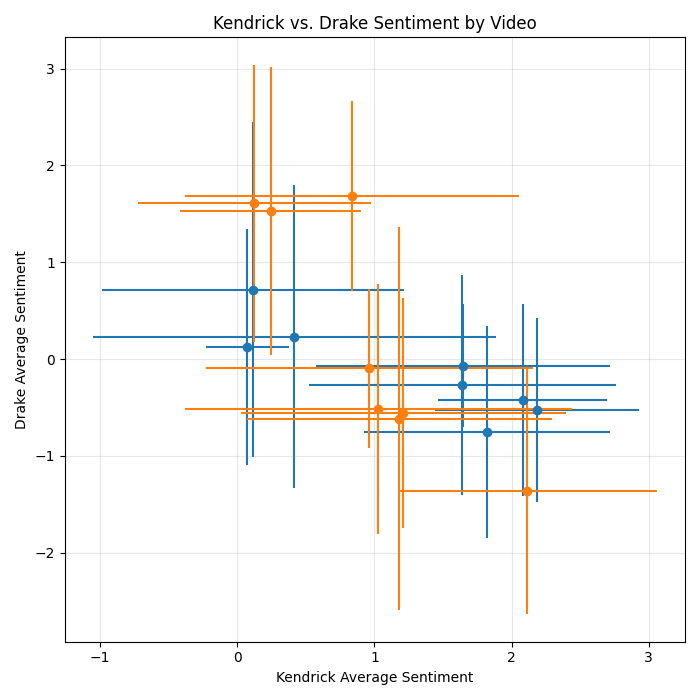

In [41]:
plt.close('all')
plt.figure(figsize=(7, 7))
for orientation in ['Kendrick', 'Drake']:
    group = sentiment_by_video[sentiment_by_video['orientation'] == orientation]
    plt.errorbar(group['kendrick_mean'], group['drake_mean'], yerr=group['drake_std'], xerr=group['kendrick_std'],
        fmt='o', alpha=1, label=orientation)

    # labeling each point with its video/channel identifier
    # for _, row in group.iterrows():
    #     plt.annotate(
    #         f"{row['song']}\n{row['artist']}", (row['kendrick_mean'], row['drake_mean']), fontsize=7, xytext=(4, 4), textcoords='offset points')

plt.xlabel("Kendrick Average Sentiment")
plt.ylabel("Drake Average Sentiment")
plt.grid(True, alpha=0.3)
plt.title("Kendrick vs. Drake Sentiment by Video")
plt.tight_layout()
plt.show()

### Now that I have the average sentiment score and standard deviation of the score, we can perform PCA on the data to see how the orientation of the channel influences the sentiment scores

(16, 4)
[[ 0.67939677 -0.58640442 -0.01884601 -0.4406753 ]
 [ 0.04089515 -0.30884577  0.84328479  0.4379642 ]
 [ 0.05157752 -0.45523969 -0.53707333  0.70827171]
 [ 0.73081282  0.59455948  0.00823544  0.3351773 ]]
PC1: 0.487
PC2: 0.272
PC3: 0.196
PC4: 0.045


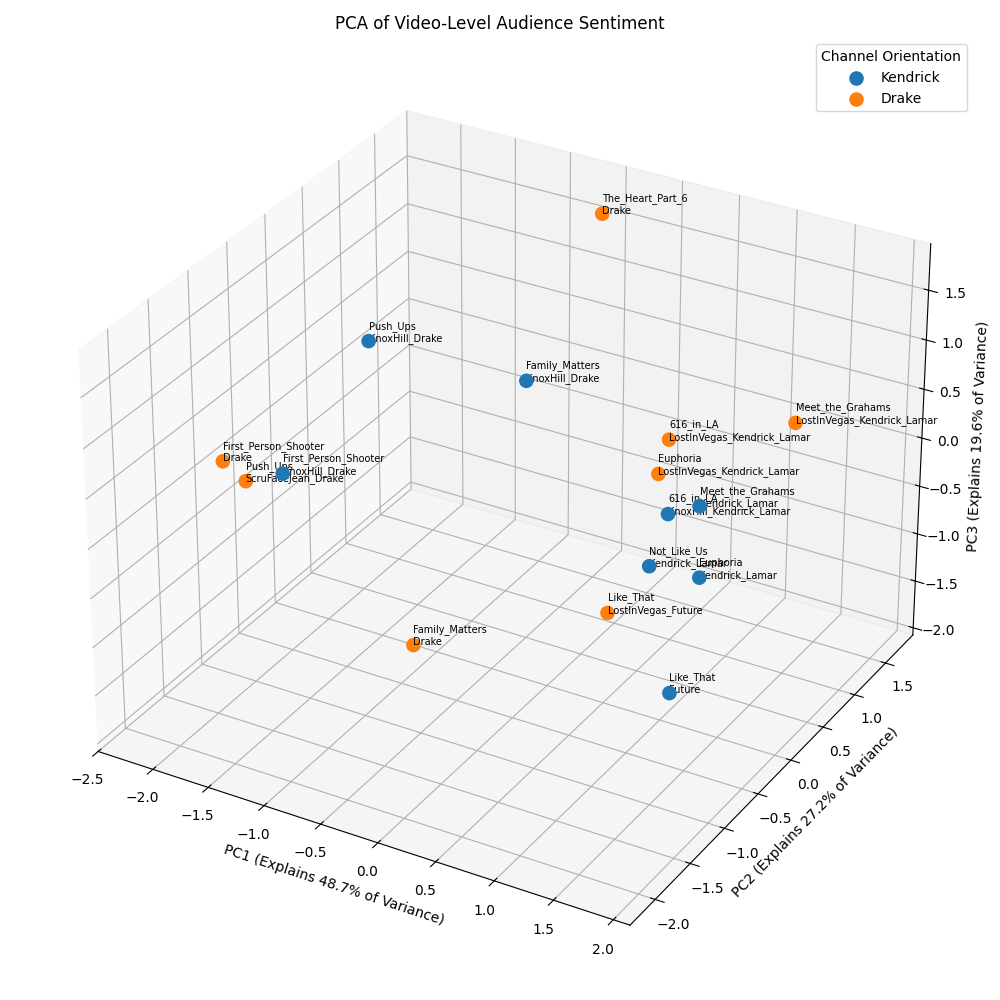

In [ ]:
from mpl_toolkits import mplot3d
%matplotlib widget

#pca data
pca_data = sentiment_by_video[['kendrick_mean', 'drake_mean', 'kendrick_std', 'drake_std']].copy()

#performing the pca on the dataset
Xs = StandardScaler().fit_transform(pca_data) # center, scale each column
pca = PCA()
Z = pca.fit_transform(Xs)
print(Z.shape)
variances = pca.explained_variance_ratio_

print(pca.components_)
for i, variance in enumerate(pca.explained_variance_ratio_):
    print(f'PC{i + 1}: {variance:.3f}')

#appending the pcs to the pca_data dataframe
pca_data['PC1'] = Z[:, 0]
pca_data['PC2'] = Z[:, 1]
pca_data['PC3'] = Z[:, 2]

#also providing the orientations, artist and song name, now that the PCA is complete, for the plot
pca_data['orientation'] = sentiment_by_video[['orientation']]
pca_data['artist'] = sentiment_by_video[['artist']]
pca_data['song'] = sentiment_by_video[['song']]


plt.close('all')
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111, projection='3d')


#for each point on the PCA, i'm coloring it by the orientation of the video and labeling 
# it with the song title and who's video it is
for orientation in ['Kendrick', 'Drake']:
    group = pca_data[pca_data['orientation'] == orientation]
    ax.scatter(group['PC1'], group['PC2'], group['PC3'], s=90, alpha=1, label=orientation)
    # labeling each point with its video/channel identifier
    for _, row in group.iterrows():
        # ax.annotate(f"{row['song']}\n{row['artist']}", (row['PC1'], row['PC2']), fontsize=7, xytext=(4, 4), textcoords='offset points')
        ax.text(row['PC1'], row['PC2'], row['PC3'], f"{row['song']}\n{row['artist']}", fontsize=7, )

ax.set_xlabel(f"PC1 (Explains {(variances[0]*100):.1f}% of Variance)")
ax.set_ylabel(f"PC2 (Explains {(variances[1]*100):.1f}% of Variance)")
ax.set_zlabel(f"PC3 (Explains {(variances[2]*100):.1f}% of Variance)")

plt.title('PCA of Video-Level Audience Sentiment')
plt.legend(title='Channel Orientation')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

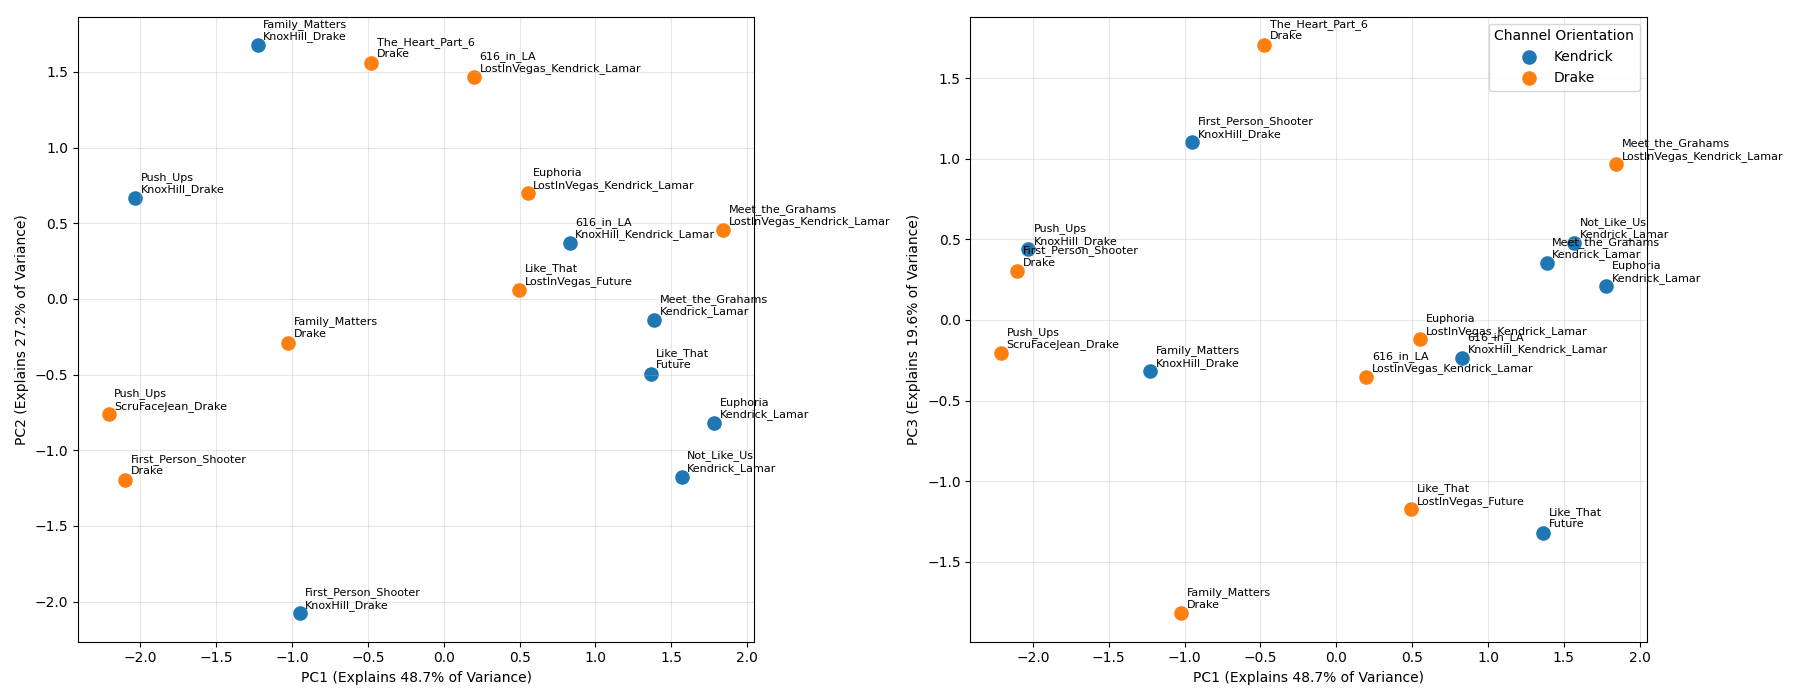

In [34]:
plt.close('all')
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7))

#for each point on the PCA, i'm coloring it by the orientation of the video and labeling 
# it with the song title and who's video it is
for orientation in ['Kendrick', 'Drake']:
    group = pca_data[pca_data['orientation'] == orientation]
    ax1.scatter(group['PC1'], group['PC2'], s=90, alpha=1, label=orientation)
    ax2.scatter(group['PC1'], group['PC3'], s=90, alpha=1, label=orientation)
    # labeling each point with its video/channel identifier
    for _, row in group.iterrows():
        ax1.annotate(f"{row['song']}\n{row['artist']}", (row['PC1'], row['PC2']), fontsize=8, xytext=(4, 4), textcoords='offset points')
        ax2.annotate(f"{row['song']}\n{row['artist']}", (row['PC1'], row['PC3']), fontsize=8, xytext=(4, 4), textcoords='offset points')


ax1.set_xlabel(f"PC1 (Explains {(variances[0]*100):.1f}% of Variance)")
ax1.set_ylabel(f"PC2 (Explains {(variances[1]*100):.1f}% of Variance)")

ax2.set_xlabel(f"PC1 (Explains {(variances[0]*100):.1f}% of Variance)")
ax2.set_ylabel(f"PC3 (Explains {(variances[2]*100):.1f}% of Variance)")

plt.legend(title='Channel Orientation')
ax1.grid(True, alpha=0.3)
ax2.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

[0.49 0.27 0.2  0.04]
[0.49 0.76 0.96 1.  ]


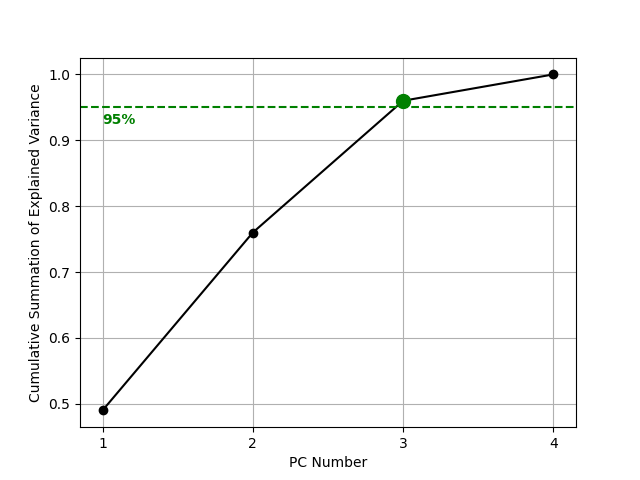

In [37]:
#From PCA above, I'm going to plot the cumulative sum of the PCAs to see when it crosses the threshold
threshold = 0.95 #95%

variances = pca.explained_variance_ratio_
print(variances.round(2))
cumsum = np.cumsum(variances).round(2)
print(cumsum)

pcs = range(1, 5)
plt.close('all')
plt.plot(pcs, cumsum, marker='o', c='k')
plt.axhline(y=threshold, ls='--', c='green')
plt.text(x=1, y=threshold-0.025, s='95%', weight='bold', color='green')
plt.scatter(3, cumsum[2], marker='o', color='green', s=100, zorder=99)
plt.xticks([1, 2, 3, 4])

plt.grid(True)
plt.xlabel("PC Number")
plt.ylabel("Cumulative Summation of Explained Variance")
plt.show()